## SEB and IBPM analysis

In [1]:
import os
import glob

import math
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy as cart
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
import seaborn as sns

import numpy as np
import xarray as xr
import cftime
import pandas as pd

import dask

# regime_limit now imported from lumip_utils (see lumip_utils.py; defaults to
# method="raw", non-deseasonalized, per explicit user request -- see REVISION_NOTES.md)
from lumip_utils import regime_limit


In [2]:
# NOTE (revision): data_path/out_path for "locale_mc" fixed from the stale
# .../Desktop/afforestation_LUMIP/... in the original to .../Documents/afforestation_LUMIP/...
# -- that's where the data actually lives; the original path would have failed on the
# very first data-loading cell below.
work = "locale_mc" # or "levante"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/" \
    "Figures/"

## Functions

In [3]:
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")
    
    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")
    
    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))
    
    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

In [4]:
def get_pixel_area(ds):
    """Calculate the area of each pixel in m^2 given latitudes and longitudes."""
    lat = ds.lat.values
    lon = ds.lon.values
    # Earth radius in meters
    R = 6.371e6
    rad = (2 * math.pi / 360)  # Convert degrees to radians

    # Reshape lat and lon to make sure they have the correct shape
    if lat[0] > lat[-1]:
        lat = lat[::-1]

    # Calculate the area of each pixel
    pixel_areas = np.zeros((len(lat) - 1, len(lon) - 1))
    for i in range(len(lat) - 1):
        for j in range(len(lon) - 1):
            pixel_areas[i, j] = (R ** 2 *
                                 (math.sin(rad * lat[i + 1]) - math.sin(rad * lat[i])) *
                                 abs(lon[j + 1] - lon[j]) * rad)

    pixel_areas = xr.DataArray(pixel_areas, coords=[lat[:-1], lon[:-1]], dims=["lat", "lon"])
    return pixel_areas

def cell_weight(ds):
    R = 6.371e6
    dϕ = np.deg2rad(ds.lat[1] - ds.lat[0])
    dλ = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dϕ * xr.ones_like(ds.lon)
    dlon = R * dλ * np.cos(np.deg2rad(ds.lat))
    cell_area = dlon * dlat
    return(cell_area)

def lon180(ds):
    ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
    ds = ds.sortby(ds.lon)
    return ds

In [5]:
from scipy.stats import mannwhitneyu

def mann_whitney_pvalue(arr1, arr2):
    stat, p = mannwhitneyu(arr1, arr2, alternative="two-sided")
    return p

def xr_multipletest(p, alpha=0.05, method='fdr_bh', **multipletests_kwargs):
    """Apply statsmodels.stats.multitest.multipletests for multi-dimensional xr.objects."""
    from statsmodels.stats.multitest import multipletests
    # stack all to 1d array
    p_stacked = p.stack(s=p.dims)
    # mask only where not nan: https://github.com/statsmodels/statsmodels/issues/2899
    mask = np.isfinite(p_stacked)
    pvals_corrected = np.full(p_stacked.shape, np.nan)
    reject = np.full(p_stacked.shape, np.nan)
    # apply test where mask
    reject[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[0]
    pvals_corrected[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[1]

    def unstack(reject, p_stacked):
        """Exchange values from p_stacked with reject (1d array) and unstack."""
        xreject = p_stacked.copy()
        xreject.values = reject
        xreject = xreject.unstack()
        return xreject

    reject = unstack(reject, p_stacked)
    pvals_corrected = unstack(pvals_corrected, p_stacked)
    return reject, pvals_corrected


In [6]:
def lag_linregress_3D(x, y, lagx=0, lagy=0):
    """
    Input: Two xr.Datarrays of any dimensions with the first dim being time. 
    Thus the input data could be a 1D time series, or for example, have three dimensions (time,lat,lon). 
    Datasets can be provied in any order, but note that the regression slope and intercept will be calculated
    for y with respect to x.
    Output: Covariance, correlation, regression slope and intercept, p-value, and standard error on regression
    between the two datasets along their aligned time dimension.  
    Lag values can be assigned to either of the data, with lagx shifting x, and lagy shifting y, with the specified lag amount. 
    """ 
    #1. Ensure that the data are properly alinged to each other. 
    x,y = xr.align(x,y)
    
    #2. Add lag information if any, and shift the data accordingly
    if lagx!=0:
        #If x lags y by 1, x must be shifted 1 step backwards. 
        #But as the 'zero-th' value is nonexistant, xr assigns it as invalid (nan). Hence it needs to be dropped
        x   = x.shift(time = -lagx).dropna(dim='time')
        #Next important step is to re-align the two datasets so that y adjusts to the changed coordinates of x
        x,y = xr.align(x,y)

    if lagy!=0:
        y   = y.shift(time = -lagy).dropna(dim='time')
        x,y = xr.align(x,y)
 
    #3. Compute data length, mean and standard deviation along time axis for further use: 
    n     = x.shape[0]
    xmean = x.mean(axis=0)
    ymean = y.mean(axis=0)
    xstd  = x.std(axis=0)
    ystd  = y.std(axis=0)
    
    #4. Compute covariance along time axis
    cov   =  np.sum((x - xmean)*(y - ymean), axis=0)/(n)
    
    #5. Compute correlation along time axis
    cor   = cov/(xstd*ystd)
    
    #6. Compute regression slope and intercept:
    slope     = cov/(xstd**2)
    intercept = ymean - xmean*slope
    y_pred =  intercept + slope*x
    res = y - y_pred

    #7. Compute P-value and standard error
    #Compute t-statistics
    tstats = cor*np.sqrt(n-2)/np.sqrt(1-cor**2)
    stderr = slope/tstats
    
    from scipy.stats import t
    pval   = t.sf(tstats, n-2)*2
    pval   = xr.DataArray(pval, dims=cor.dims, coords=cor.coords)

    #return cov,cor,slope,intercept,pval,stderr
    results = {}
    results["cor"] = cor
    results["coef"] = slope
    results["pval"] = pval
    return results

## Import preprocessed data

In [159]:
models = [ "ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

In [160]:
scenario = 'ssp126Lu'
xr_aff = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_aff.append(content)


scenario = 'ssp370'
xr_ctl = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_ctl.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade perfo

In [161]:
scenario = 'ssp126Lu'
xr_aff_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_aff_pft.append(content)


scenario = 'ssp370'
xr_ctl_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_ctl_pft.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3490561412.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade pe

### Data homogenization

In [162]:
# CanESM5 does not provide Latent Heat
# We derive it as Rn - H (ignoring Ground Heat fluxes that are negligible over land)

xr_ctl[3]["hfls"] = (xr_ctl[3].rsds - xr_ctl[3].rlds) - xr_ctl[3].hfss
xr_aff[3]["hfls"] = (xr_aff[3].rsds - xr_aff[3].rlds) - xr_aff[3].hfss

# Rename ta to tas 
xr_aff[3] = xr_aff[3].rename({"ta":"tas"})
xr_ctl[3] = xr_ctl[3].rename({"ta":"tas"})

# Select the first pressure level
xr_aff[3] = xr_aff[3].isel(plev = 0)
xr_ctl[3] = xr_ctl[3].isel(plev = 0)

# Try to interpolate surface temperature for CanESM5
xr_ctl[3]["tas"] = (xr_ctl[3].ts + xr_ctl[3].tas)/2
xr_aff[3]["tas"] = (xr_aff[3].ts + xr_aff[3].tas)/2


In [163]:
# Convert pr and evspsbl from kg m-2 s-1 to mm month-1
for i,mm in enumerate(models):
    xr_ctl[i]["pr"] = xr_ctl[i].pr*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["pr"] = xr_aff[i].pr*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["pr"].attrs=dict(units="mm/months")
    xr_aff[i]["pr"].attrs=dict(units="mm/months")

    if mm == "CMCC-ESM2" or "CESM2": # LE in W*m^2; λ is in MJ kg-1 = MW*s kg-1 
        # https://earthscience.stackexchange.com/questions/20733/fluxnet15-how-to-convert-latent-heat-flux-to-actual-evapotranspiration
        xr_ctl[i]["evspsbl"] = xr_ctl[i].hfls/(2.501 - (2.361e-3) * (xr_ctl[i].tas-273.15))*10**6
        xr_aff[i]["evspsbl"] = xr_aff[i].hfls/(2.501 - (2.361e-3) * (xr_aff[i].tas-273.15))*10**6

    else:
        None
    
    xr_ctl[i]["evspsbl"] = xr_ctl[i].evspsbl*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["evspsbl"] = xr_aff[i].evspsbl*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["evspsbl"].attrs=dict(units="mm/months")
    xr_aff[i]["evspsbl"].attrs=dict(units="mm/months")
    
    xr_aff[i]["albedo"] = xr_aff[i].rsus / xr_aff[i].rsds
    xr_ctl[i]["albedo"] = xr_ctl[i].rsus / xr_ctl[i].rsds
    
    

In [164]:
# Homogenize lat and lon
for i,mm in enumerate(models):
    content = xr_aff[i]
    xr_aff_pft[i]["lat"] = content.tas.lat; xr_aff_pft[i]["lon"] = content.lon

    content = xr_ctl[i]
    xr_ctl_pft[i]["lat"] = content.tas.lat; xr_ctl_pft[i]["lon"] = content.lon

#### Delta

In [165]:
xr_delta = []
xr_delta_pft = []
for i,mm in enumerate(models):
    xr_delta.append(xr_aff[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))
    xr_delta_pft.append(xr_aff_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))


In [166]:
xr_mw_ts = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_mw_ts"+mm+".nc"))[0]                                      
    content = xr.open_dataarray(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})

    xr_mw_ts.append(content)

## Import Growing season data

AFF, CTL and DELTA growing season datasets are computed by taking the average of the 2070-2100 climatology only considering the months between growing season onset and offest. 

Method developed from Peano et al. (2019) an Tortarolo et al. (2013)

In [167]:
xr_delta_gs = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_delta_gs_" + mm + '.nc'))[0]     ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4')
    content = content.assign_attrs(esm = mm)
    xr_delta_gs.append(content)

xr_aff_gs = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_aff_gs_" + mm + '.nc'))[0]     ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4')
    content = content.assign_attrs(esm = mm)
    xr_aff_gs.append(content)

xr_ctl_gs = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_ctl_gs_" + mm + '.nc'))[0]     ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4')
    content = content.assign_attrs(esm = mm)
    xr_ctl_gs.append(content)

## Afforestation masking

In [168]:
for m, mm in enumerate (models): 

    mask_treefrac_pos = [ds["treeFrac"].where(ds["treeFrac"] > 10) for ds in xr_delta_pft]
    mask_treefrac_neg = [ds["treeFrac"].where(ds["treeFrac"] < -10) for ds in xr_delta_pft]

In [169]:
# Mask global land area from LAI (from LandMask file for CanESM5)
landmask = xr.open_dataset(glob.glob(os.path.join(data_path + "LandMasks/" + "sftlf_fx_CanESM5_ssp126_r1i1p2f1_gn.nc"))[0],engine = 'netcdf4',chunks={"time": 240})
landmask = lon180(landmask).sftlf 
landmask = landmask.sel(lat = slice(-60, 90))
lands = [a.lai.isel(time = 0).where(a.lai.isel(time = 0) != np.nan) for a in xr_aff]
lands[3] = landmask.where(landmask != 0)
lands = [xr.where(~np.isnan(a), 1, np.nan) for a in lands]

for m,mm in enumerate(models):
    # Get the pixel area for the mask's lat/lon grid
    pixel_areas = get_pixel_area(mask_treefrac_pos[m])

    # Mask the pixel areas
    masked_areas = pixel_areas.where(~np.isnan(mask_treefrac_pos[m]))

    # Global land surface
    global_land = pixel_areas.where(~np.isnan(lands[m]))

    # Calculate the % area
    perc_area = (masked_areas.sum().values / global_land.sum().values) *100

    # Convert from % to Mkm^2
    total_area_km2 = (perc_area/100 * 150) - 2.17

    print("Area of Delta_treefrac > 10% for " + mm + ": " + str(perc_area.round(0)) + " %" + "-->" + str(total_area_km2.round(1)) + "Mkm2")


Area of Delta_treefrac > 10% for ACCESS-ESM1-5: 8.0 %-->9.8Mkm2
Area of Delta_treefrac > 10% for CMCC-ESM2: 14.0 %-->19.5Mkm2
Area of Delta_treefrac > 10% for CESM2: 14.0 %-->19.3Mkm2
Area of Delta_treefrac > 10% for CanESM5: 7.0 %-->8.9Mkm2
Area of Delta_treefrac > 10% for IPSL-CM6A-LR: 11.0 %-->14.1Mkm2
Area of Delta_treefrac > 10% for MPI-ESM1-2-LR: 12.0 %-->15.6Mkm2
Area of Delta_treefrac > 10% for UKESM1-0-LL: 8.0 %-->9.6Mkm2


## Regime masking

In [170]:
# regime_limit is now imported from lumip_utils (method="raw" default, drop=False preserved) -- see import cell above. Local definition removed.

In [183]:
mask_aff_water = []
mask_aff_energy = []
mask_ctl_water = []
mask_ctl_energy = []

for m, mm in enumerate(models):
    aff_future = xr_aff[m].sel(time=slice("2071-01", "2100-12"))
    ctl_future = xr_ctl[m].sel(time=slice("2071-01", "2100-12"))

    water, energy = regime_limit(aff_future)
    mask_aff_water.append(water)
    mask_aff_energy.append(energy)

    water, energy = regime_limit(ctl_future)
    mask_ctl_water.append(water)
    mask_ctl_energy.append(energy)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


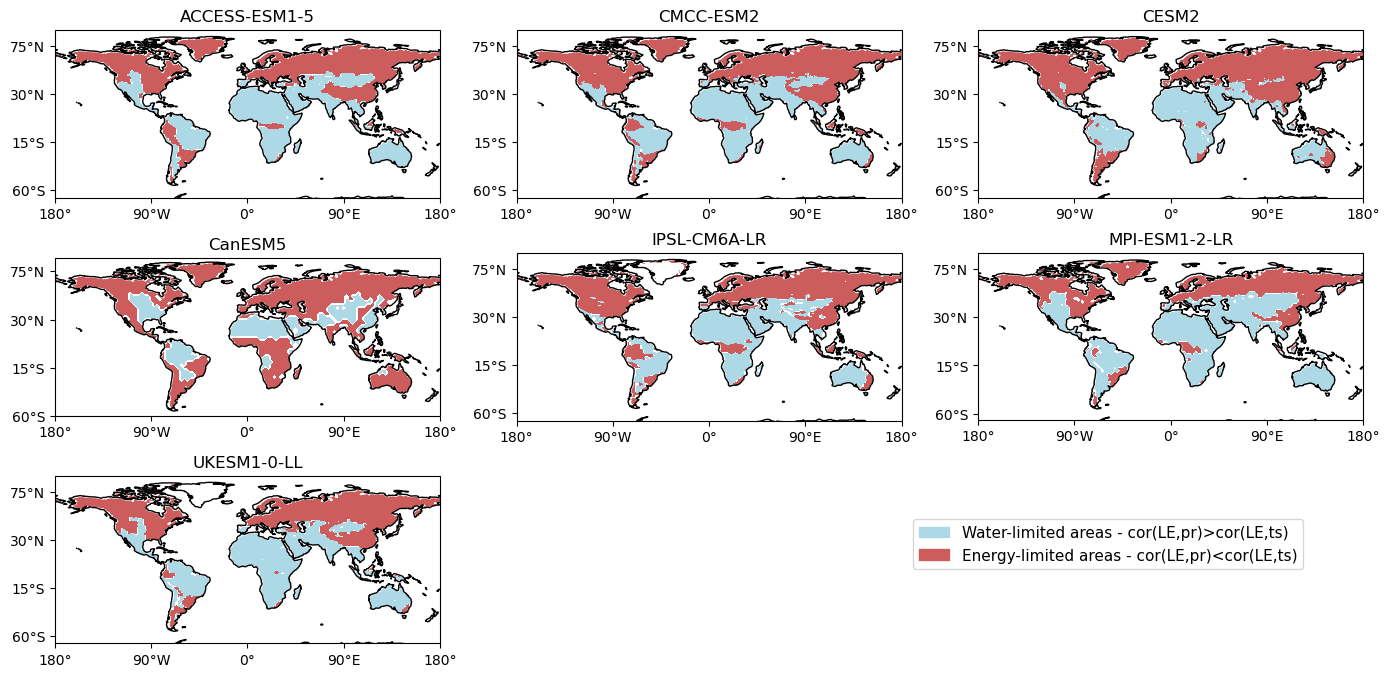

In [ ]:
import matplotlib.patches as mpatches

water_patch = mpatches.Patch(color='lightblue', label='Water-limited areas - cor(LE,pr)>cor(LE,ts)')
energy_patch = mpatches.Patch(color='indianred', label='Energy-limited areas - cor(LE,pr)<cor(LE,ts)')

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
for i,_ in enumerate(models):
    
    data = mask_aff_water[i]#.isel(time = -1)
    lats = data.lat
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, transform = ccrs.PlateCarree(), colors="lightblue")

    data = mask_aff_energy[i]#.isel(time = -1)  
    lats = data.lat
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])
    map = axs[i].contourf(lons, lats, data, transform = ccrs.PlateCarree(), colors = "indianred")

    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(models[i])

# # Delete the unwanted axes
for i in [7,8]:
    fig.delaxes(axs[i])
        
fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)
fig.tight_layout()

# Add the legend
fig.legend(handles=[water_patch, energy_patch], loc='lower right', bbox_to_anchor=(0.94, 0.2), ncol=1, fontsize = 11)

title = "water_energy_lim_ssp126Lu_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

## treeFrac change

### regime and afforestation

In [ ]:
import numpy as np

aff_water_percentage = {}

for i, mm in enumerate(models):
    # 1. Define the masks for the current model
    # .notnull() assumes your masks have values where True and NaN elsewhere
    is_afforested = mask_treefrac_pos[i].notnull()
    is_water_limited = mask_aff_water[i].notnull()
    
    # 2. Find the intersection (Both must be True)
    overlap = is_afforested & is_water_limited
    
    # 3. Calculate weights (Cosine of latitude)
    # This ensures a grid cell at the equator counts more than one at 80N
    weights = np.cos(np.deg2rad(is_afforested.lat))
    
    # 4. Calculate weighted sums
    # We sum the weights where the condition is True
    total_aff_area = weights.where(is_afforested).sum()
    overlap_area = weights.where(overlap).sum()
    
    # 5. Calculate percentage
    if total_aff_area > 0:
        percentage = (overlap_area / total_aff_area) * 100
    else:
        percentage = 0
        
    aff_water_percentage[mm] = percentage.values.item()
    print(f"{mm}: {aff_water_percentage[mm]:.2f}% of afforested land is water-limited")

ACCESS-ESM1-5: 42.03% of afforested land is water-limited
CMCC-ESM2: 52.11% of afforested land is water-limited
CESM2: 58.67% of afforested land is water-limited
CanESM5: 15.31% of afforested land is water-limited
IPSL-CM6A-LR: 55.24% of afforested land is water-limited
MPI-ESM1-2-LR: 73.42% of afforested land is water-limited
UKESM1-0-LL: 64.94% of afforested land is water-limited


SSP370

<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/493548318.py:46: SyntaxWarning: invalid escape sequence '\D'
  cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries,

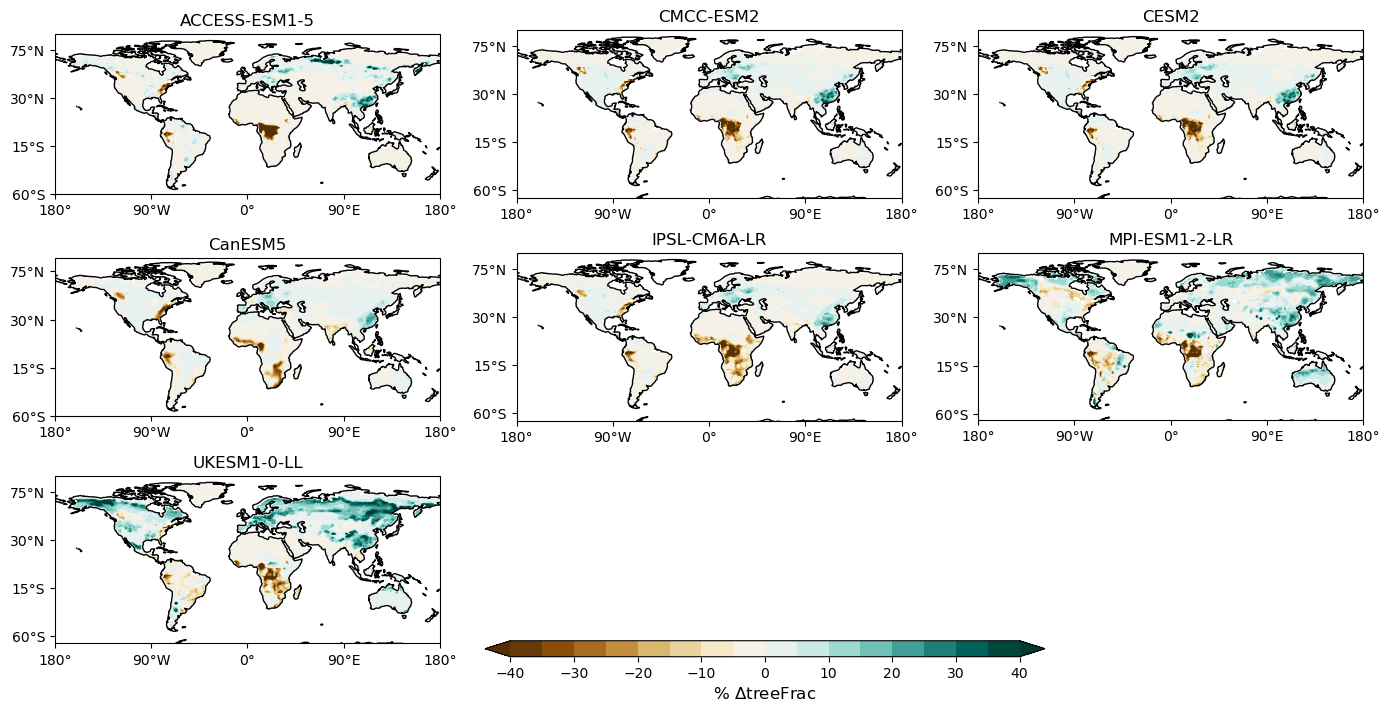

In [ ]:
## luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

vars_plot = "treeFrac"
cmap = "BrBG"
clevs=np.arange(-40,41,5)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
for i,_ in enumerate(models):
    
    data = (xr_ctl_pft[i].isel(time = -1).treeFrac - xr_ctl_pft[i].isel(time = 0).treeFrac)   # data = to_plot[1].isel(time = -1)[vv]
    lats = data.lat
        
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(models[i])

# # Delete the unwanted axes
for i in [7,8]:
    fig.delaxes(axs[i])
        
fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)

fig.tight_layout()

title = "delta_treeFrac_ssp370_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

ssp126

<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3304966693.py:46: SyntaxWarning: invalid escape sequence '\D'
  cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries

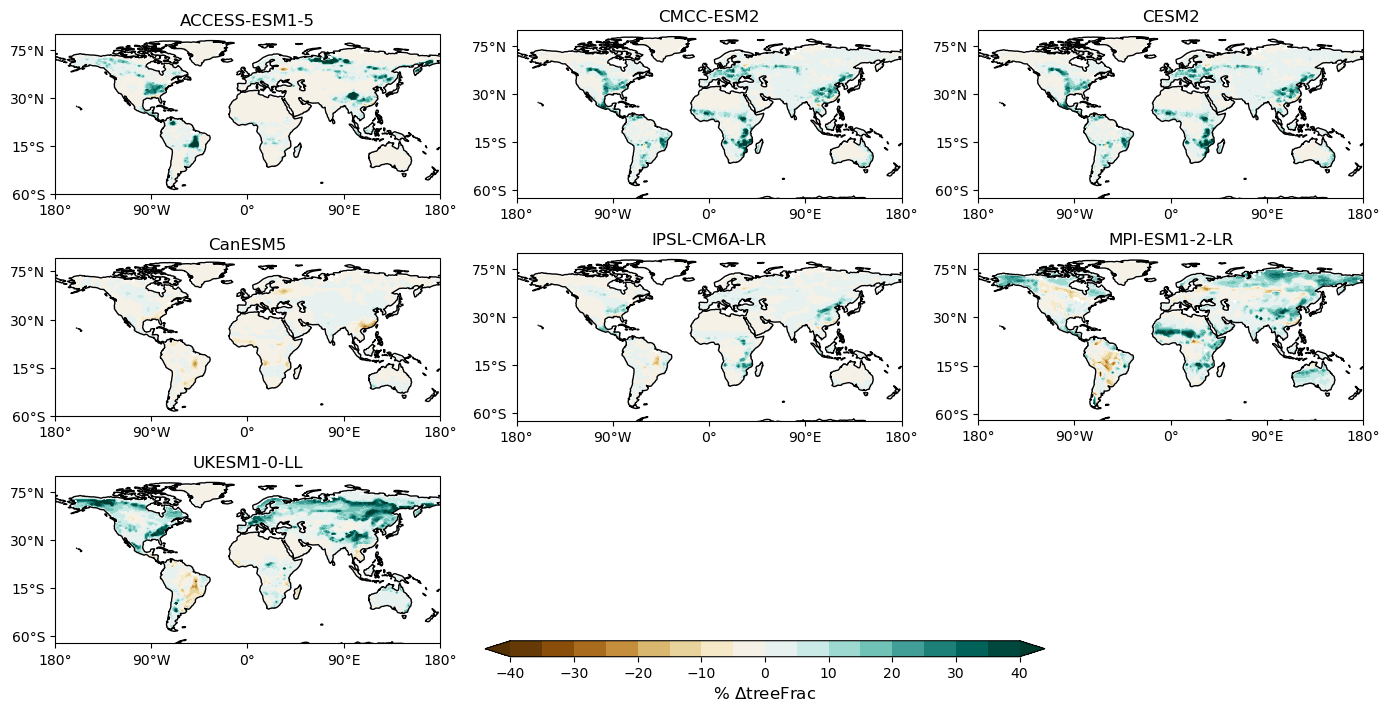

In [ ]:
## luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

vars_plot = "treeFrac"
cmap = "BrBG"
clevs=np.arange(-40,41,5)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
for i,_ in enumerate(models):
    
    data = (xr_aff_pft[i].isel(time = -1).treeFrac - xr_aff_pft[i].isel(time = 0).treeFrac)   # data = to_plot[1].isel(time = -1)[vv]
    lats = data.lat
        
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(models[i])

# # Delete the unwanted axes
for i in [7,8]:
    fig.delaxes(axs[i])
        
fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)

fig.tight_layout()

title = "delta_treeFrac_ssp126_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

A/R scenario

<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/2943510933.py:46: SyntaxWarning: invalid escape sequence '\D'
  cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries

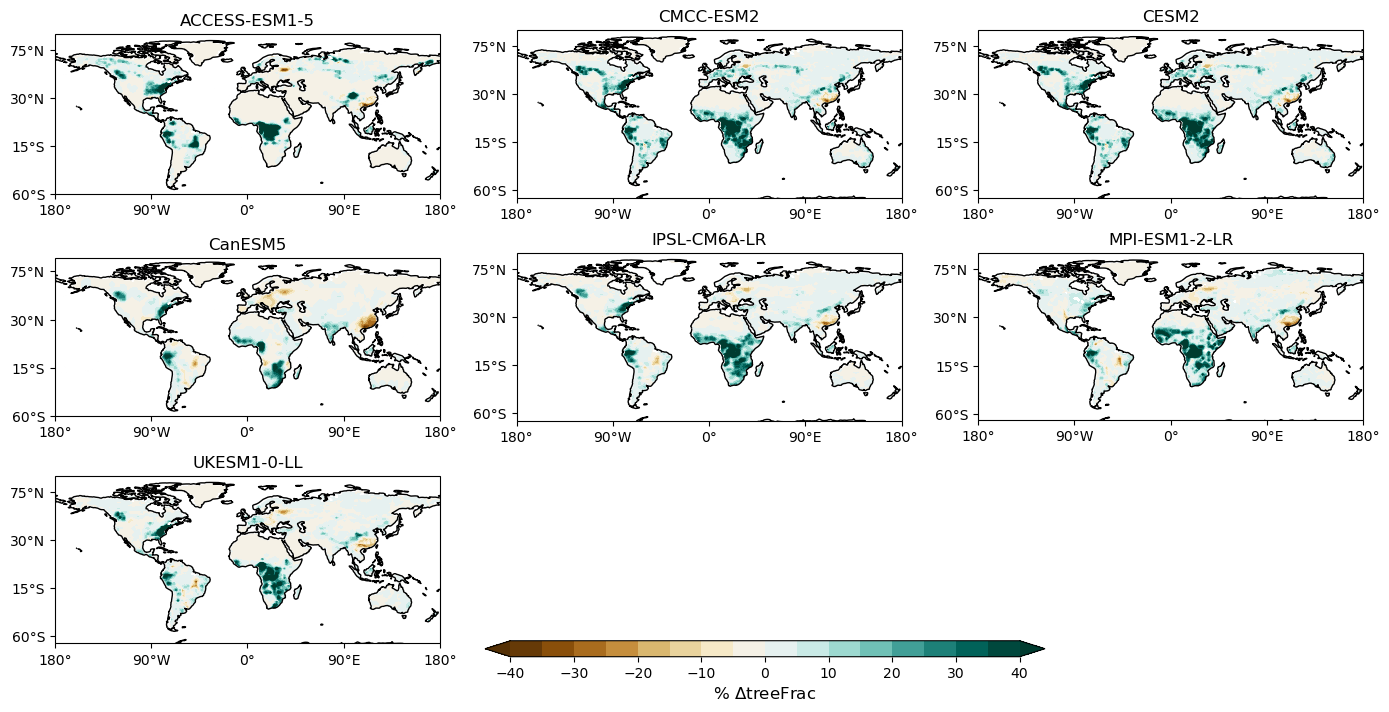

In [ ]:
## luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

vars_plot = "treeFrac"
cmap = "BrBG"
clevs=np.arange(-40,41,5)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
for i,_ in enumerate(models):
    
    data = (xr_aff_pft[i].isel(time = -1).treeFrac - xr_ctl_pft[i].isel(time = -1).treeFrac)    # data = to_plot[1].isel(time = -1)[vv]
    lats = data.lat
        
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(models[i])

# # Delete the unwanted axes
for i in [7,8]:
    fig.delaxes(axs[i])
        
fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("% $\Delta$treeFrac", fontsize=12)

fig.tight_layout()

title = "delta_treeFrac_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

## Temperature response

In [ ]:
# %%capture
for m,mm in enumerate(models):
    # Cell-area weighted mean
    pixel_area = get_pixel_area(xr_delta_gs[m])

    ts = xr_delta_gs[m].ts.weighted(pixel_area).mean(["lat","lon"]).data#.compute()
    tas = xr_delta_gs[m].tas.weighted(pixel_area).mean(["lat","lon"]).data#.compute()

    print("Global Ts diff for " + mm + ": " + str(ts.round(3)) + "K")
    print("Global Tas diff for " + mm + ": " + str(tas.round(3)) + "K")

Global Ts diff for ACCESS-ESM1-5: 0.088K
Global Tas diff for ACCESS-ESM1-5: 0.091K
Global Ts diff for CMCC-ESM2: 0.132K
Global Tas diff for CMCC-ESM2: 0.137K
Global Ts diff for CESM2: 0.009K
Global Tas diff for CESM2: 0.016K
Global Ts diff for CanESM5: -0.005K
Global Tas diff for CanESM5: -0.006K
Global Ts diff for IPSL-CM6A-LR: -0.041K
Global Tas diff for IPSL-CM6A-LR: -0.034K
Global Ts diff for MPI-ESM1-2-LR: -0.028K
Global Tas diff for MPI-ESM1-2-LR: -0.015K
Global Ts diff for UKESM1-0-LL: 0.022K
Global Tas diff for UKESM1-0-LL: 0.029K


Test the significance with Mann-Whitney U test

In [ ]:
xr_mw_ts = []

for i, mm in enumerate(models):
    aff = xr_aff[i].sel(time=slice("2071", "2100")).ts.fillna(0).compute()
    ctl = xr_ctl[i].sel(time=slice("2071", "2100")).ts.fillna(0).compute()
    aff = aff#.chunk({"time": -1})
    ctl = ctl#.chunk({"time": -1})

    pval = xr.apply_ufunc(
        mann_whitney_pvalue,
        aff,
        ctl,
        input_core_dims=[["time"], ["time"]],
        output_core_dims=[[]],
        vectorize=True,
        # dask="parallelized",
        output_dtypes=[float]
    )
    
    pval.name = "p_value"
    pval = pval.assign_coords(lat=aff.lat, lon=aff.lon)

    xr_mw_ts.append(pval)

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


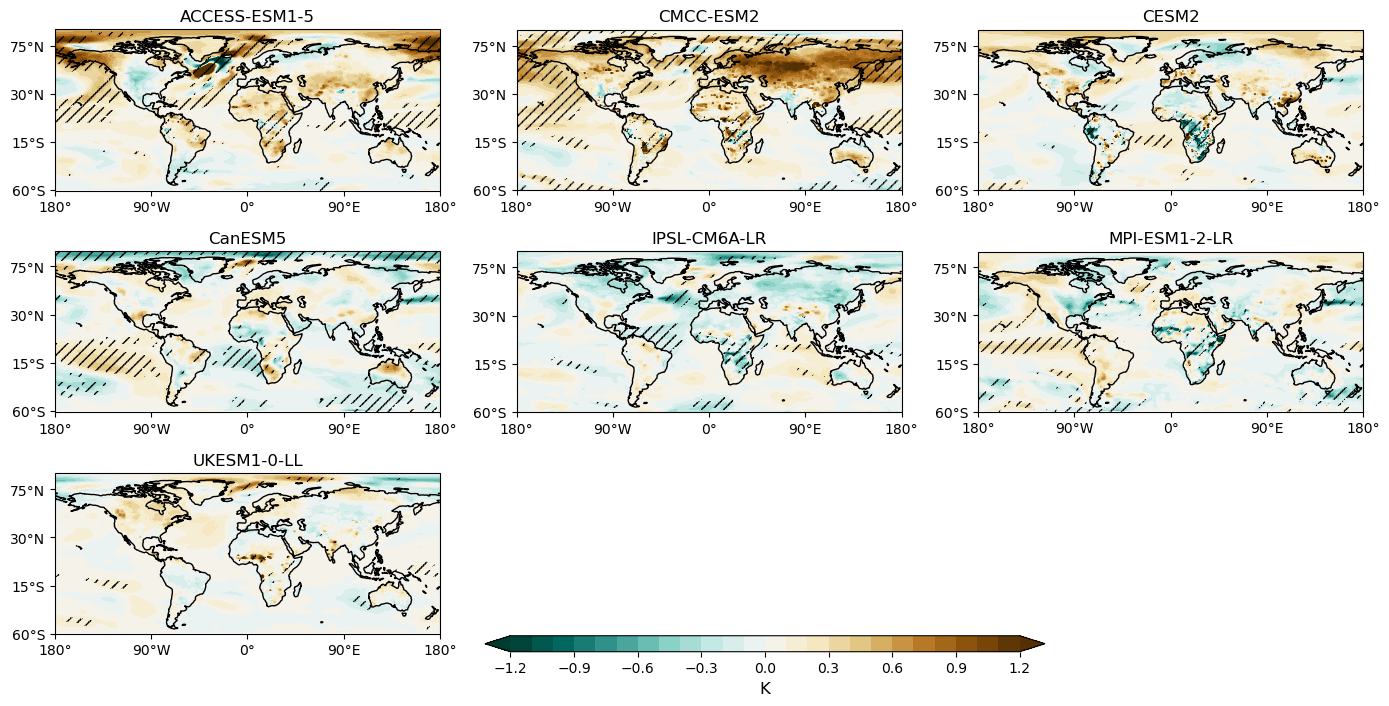

In [ ]:
# luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

cmap = "BrBG_r"
clevs=np.arange(-1.2,1.3,0.1)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
for i in np.arange(len(models)):
    
    data = (xr_aff[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts - 
            xr_ctl[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts)
    lats = data.lat
    
    hatch = xr_mw_ts[i]
    
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    # axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    sign = np.ma.masked_greater(hatch, 0.1)
    map1 = axs[i].pcolor(lons, lats, sign, hatch = '///', transform = ccrs.PlateCarree(), alpha=0)
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(models[i])
    
    # axs[i].label_outer()
    
for i in [7,8]:
    fig.delaxes(axs[i])
        

fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("K", fontsize=12)

fig.tight_layout()

title = "Ts_esm_mw_0.1_grow_seas"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

### Ts in regions of Afforestation

In [ ]:
ts_aff_mean = []
# ts_aff_energy_mean = []
ts_aff_mw = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() #& mask_aff_water[m].notnull()
    # mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    mask2 = mask_treefrac_pos[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask

    # data = (xr_aff[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts - 
    #         xr_ctl[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts)
    
    data = xr_delta[m].ts#.compute()

    masked = data.where(mask)
    # masked1 = data.where(mask1)
    masked2 = data.where(mask2)

    print("% of afforestation cells with significant Ts difference: " + mm + " " + str((masked2.count().values.sum()/mask_treefrac_pos[m].count().values.sum()*100).round(0)) + "%")

    content = np.array(masked.weighted(get_pixel_area(masked)).mean(["lat","lon"]).values)
    # content1 = np.array(masked1.weighted(get_pixel_area(masked1)).mean(["lat","lon"]).values)
    content2 = np.array(masked2.weighted(get_pixel_area(masked2)).mean(["lat","lon"]).values)

    print("Ts in afforested cells: " + mm + " " + str((content2).round(3)) + "K")

    ts_aff_mean.append(content)
    # ts_aff_energy_mean.append(content1)
    ts_aff_mw.append(content2)


ts_aff_mean = pd.DataFrame(ts_aff_mean, index = models)
# ts_aff_energy_mean = pd.DataFrame(ts_aff_energy_mean, index = models)
ts_aff_mw = pd.DataFrame(ts_aff_mw, index = models)

% of afforestation cells with significant Ts difference: ACCESS-ESM1-5 23.0%
Ts in afforested cells: ACCESS-ESM1-5 -0.14K
% of afforestation cells with significant Ts difference: CMCC-ESM2 34.0%
Ts in afforested cells: CMCC-ESM2 -0.092K
% of afforestation cells with significant Ts difference: CESM2 45.0%
Ts in afforested cells: CESM2 -0.753K
% of afforestation cells with significant Ts difference: CanESM5 16.0%
Ts in afforested cells: CanESM5 -0.312K
% of afforestation cells with significant Ts difference: IPSL-CM6A-LR 37.0%
Ts in afforested cells: IPSL-CM6A-LR -0.548K
% of afforestation cells with significant Ts difference: MPI-ESM1-2-LR 49.0%
Ts in afforested cells: MPI-ESM1-2-LR -0.831K
% of afforestation cells with significant Ts difference: UKESM1-0-LL 6.0%
Ts in afforested cells: UKESM1-0-LL 0.17K


In [ ]:
ts_aff_water_mean["regime"] = "water-lim"
ts_aff_energy_mean["regime"] = "energy-lim"

ts_aff = pd.concat([ts_aff_water_mean, ts_aff_energy_mean], axis = 0)
ts_aff.columns = ["value", "regime"]
ts_aff = ts_aff.reset_index().rename(columns = {"index":"models"})
ts_aff_mean = ts_aff.groupby(['models'])['value'].mean().reset_index()

ts_aff_mw = ts_aff_mw.reset_index().rename(columns = {"index":"models"})
ts_aff_mw.columns = ["models", "value"]

NameError: name 'ts_aff_water_mean' is not defined

In [ ]:
ts_aff_mean_gs = []
# ts_aff_energy_mean = []
ts_aff_mw_gs = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() #& mask_aff_water[m].notnull()
    # mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    mask2 = mask_treefrac_pos[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask

    # data = (xr_aff[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts - 
    #         xr_ctl[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts)
    
    data = xr_delta_gs[m].ts#.compute()

    masked = data.where(mask)
    # masked1 = data.where(mask1)
    masked2 = data.where(mask2)

    print("% of afforestation cells with significant Ts difference: " + mm + " " + str((masked2.count().values.sum()/mask_treefrac_pos[m].count().values.sum()*100).round(0)) + "%")

    content = np.array(masked.weighted(get_pixel_area(masked)).mean(["lat","lon"]).values)
    # content1 = np.array(masked1.weighted(get_pixel_area(masked1)).mean(["lat","lon"]).values)
    content2 = np.array(masked2.weighted(get_pixel_area(masked2)).mean(["lat","lon"]).values)

    print("Ts in afforested cells: " + mm + " " + str((content2).round(3)) + "K")

    ts_aff_mean_gs.append(content)
    # ts_aff_energy_mean.append(content1)
    ts_aff_mw_gs.append(content2)


ts_aff_mean_gs = pd.DataFrame(ts_aff_mean_gs, index = models)
# ts_aff_energy_mean = pd.DataFrame(ts_aff_energy_mean, index = models)
ts_aff_mw_gs = pd.DataFrame(ts_aff_mw_gs, index = models)
ts_aff_mw_gs = ts_aff_mw_gs.reset_index(names="models")
ts_aff_mw_gs.rename(columns={0: "value"}, inplace=True)

% of afforestation cells with significant Ts difference: ACCESS-ESM1-5 23.0%
Ts in afforested cells: ACCESS-ESM1-5 -0.145K
% of afforestation cells with significant Ts difference: CMCC-ESM2 34.0%
Ts in afforested cells: CMCC-ESM2 -0.091K
% of afforestation cells with significant Ts difference: CESM2 45.0%
Ts in afforested cells: CESM2 -0.717K
% of afforestation cells with significant Ts difference: CanESM5 16.0%
Ts in afforested cells: CanESM5 -0.31K
% of afforestation cells with significant Ts difference: IPSL-CM6A-LR 37.0%
Ts in afforested cells: IPSL-CM6A-LR -0.55K
% of afforestation cells with significant Ts difference: MPI-ESM1-2-LR 49.0%
Ts in afforested cells: MPI-ESM1-2-LR -0.83K
% of afforestation cells with significant Ts difference: UKESM1-0-LL 6.0%
Ts in afforested cells: UKESM1-0-LL 0.17K


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1749953912.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax0 = sns.barplot(
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1749953912.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


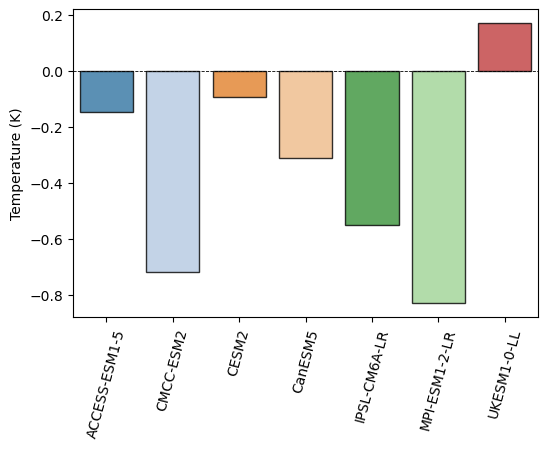

In [ ]:
import seaborn as sns

fig = plt.figure(figsize=(6, 4))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=ts_aff_mw_gs.sort_values("models"), # errorbar=("pi", 50),
        x="models", y="value",palette="tab20", edgecolor='black',
       alpha=.8,
    )
ax0.axhline(0, color = "black", linestyle = "--", lw = 0.6)
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.45, 0.1)
# ax0.legend(loc='upper left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Temperature (K)")
title = "Temperature response in afforested regions"
# ax0.set_title(title)
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

In [ ]:
%%capture
regions = ["NA", "AFR", "SE Asia", "SA", "EUR"]
    
boxes = [
        (-130, -60, 30, 60),    # NA
        (-20, 50, -25, 20),     # Africa
        (90, 130, 10, 40),       # SEAsia
        (-85, -35, -40, 10),       # SA
        (10, 60, 40, 70)       # Eurasia
]
Ts_regions_esm = []
for m,mm in enumerate(models):
    content_pos = []
    content_neg = []

    data = (xr_aff[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts - 
            xr_ctl[m].sel(time = slice("2071-01","2100-12")).mean(dim = "time").ts)

    for b in boxes:
        # np.ma.masked_less(xr_mw_ts[m], 0.1).mask to consider the significative
        masked = data.where(mask_treefrac_pos[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask).sel(lon = slice(b[0], b[1]), lat = slice(b[2], b[3]))
        content_pos.append(masked.weighted(get_pixel_area(masked)).mean().compute().data)
        
    Ts_regions_esm.append(pd.DataFrame(content_pos))

Ts_regions_esm = pd.concat(Ts_regions_esm, axis = 1).set_axis(models, axis = 1).set_axis(regions, axis = 0)
Ts_regions_esm["regions"] = Ts_regions_esm.index
Ts_regions_esm = pd.melt(Ts_regions_esm, id_vars="regions", var_name="esm")

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/2443022683.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(regions, rotation = 75)


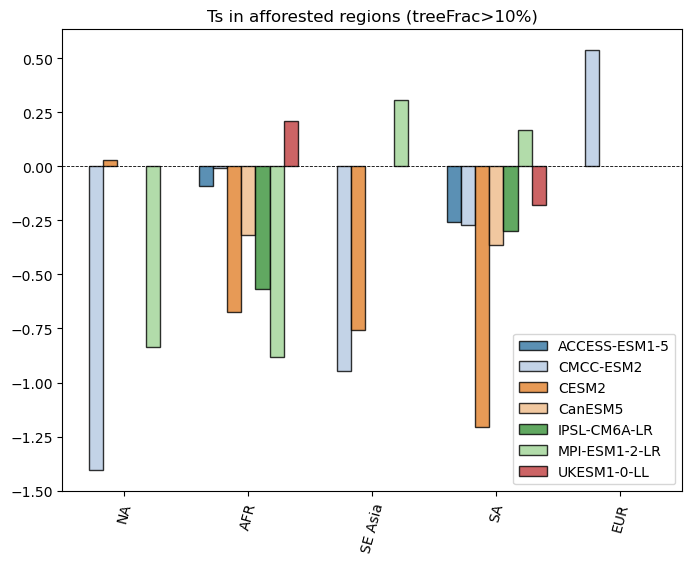

In [ ]:
fig = plt.figure(figsize=(8, 6))
ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=Ts_regions_esm, hue = "esm",# errorbar=("pi", 50),
        x="regions", y="value", edgecolor = "black",
        palette="tab20", alpha=.8, 
    )
ax0.axhline(0, color = "black", linestyle = "--", lw = 0.6)

ax0.set_xticklabels(regions, rotation = 75)
# ax0.set_ylim(-0.25, 0.25)
ax0.legend(loc='lower right', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("")
title = "Ts in afforested regions (treeFrac>10%)"
ax0.set_title(title)
output_file = os.path.join(out_path, title) + "_Regional.png"
# plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()


## Surface Energy Balance (SEB) decomposition

Taking the difference between the biogeophysical variables of ssp370-ssp126 and ssp370 \
Compute the Surface Energy Balance Decomposition to estimate the contribution to temperature.

The SEB equation can be decomposed as follows:

\begin{equation}
\Delta T_{\text{s}} = \frac{1}{{4 \varepsilon \sigma T_{\text{s}}^3}_{\text{ssp370}}} \cdot (\Delta {SW_{net}} + \Delta LW_{in} - \Delta H - \Delta \lambda E - \Delta G)
\end{equation}

that by decomposing $\Delta {SW_{net}}$ becomes:

\begin{equation}
\Delta T_{\text{s}} = \frac{1}{{4 \varepsilon \sigma T_{\text{s}}^3}_{\text{ssp370}}} \cdot (-SW_{in}\Delta {\alpha_{s}} + (1-\alpha_{ssp370})\Delta SW_{in} + \Delta LW_{in} - \Delta H - \Delta \lambda E - \Delta G)
\end{equation}

we ignore surface emissivity changes.

In [172]:
# Define Stefan-Boltzmann Constant (Wm^-2K^-4)
# Define Emissivity Constant
# Define air density Constant (Kgm^-3) (dry air, 0°C, https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6764509/)
# Define specific heat content (JKg^-1K^-1) (dry air, =0°C, https://pubs.aip.org/asa/jasa/article/76/2/555/669652/Variation-of-specific-heats-and-of-specific-heat)

sigma = 5.67*10**(-8)
eps = 0.97
rho = 1.2930
Cp = 1.0051*10**(3)

In [173]:
# Compute SEB on the last 30-yrs period (2071 - 2100)

dT_seb_esm = []
dT_model_esm = []
seb_effect_esm = []

for m,mm in enumerate(models):
    seb_effects = xr.Dataset()

    xr_aff_seb = xr_aff_gs[m] # - xr_aff.sel(time = slice("2015-01","2015-12")).mean(dim = "time") 
    xr_ctl_seb = xr_ctl_gs[m] # - xr_ctl.sel(time = slice("2015-01","2015-12")).mean(dim = "time") 

    factor = 1/(4*sigma*eps*xr_ctl_seb.ts**(3))

    Rn_aff = (xr_aff_seb.rsds - xr_aff_seb.rsus) + eps*xr_aff_seb.rlds - eps*sigma*xr_aff_seb.ts**(4)
    Rn_ctl = (xr_ctl_seb.rsds - xr_ctl_seb.rsus) + eps*xr_ctl_seb.rlds - eps*sigma*xr_ctl_seb.ts**(4)

    G_aff = Rn_aff - xr_aff_seb.hfss - xr_aff_seb.hfls
    G_ctl = Rn_ctl - xr_ctl_seb.hfss - xr_ctl_seb.hfls

    delta_Snet = factor * ((xr_aff_seb.rsds - xr_aff_seb.rsus) - (xr_ctl_seb.rsds - xr_ctl_seb.rsus))
    delta_Sd = factor * (xr_aff_seb.rsds - xr_ctl_seb.rsds) 
    delta_Ld = factor * (xr_aff_seb.rlds - xr_ctl_seb.rlds)
    delta_H = -factor * (xr_aff_seb.hfss - xr_ctl_seb.hfss)
    delta_LE = -factor * (xr_aff_seb.hfls - xr_ctl_seb.hfls)
    delta_albedo = -factor * ((xr_aff_seb.rsus/xr_aff_seb.rsds) - (xr_ctl_seb.rsus/xr_ctl_seb.rsds))

    deltaG = -factor * (G_aff - G_ctl)

    dT_seb = xr_ctl_seb.rsds*delta_albedo + (1-(xr_ctl_seb.rsus/xr_ctl_seb.rsds))*delta_Sd + delta_Ld + delta_H + delta_LE + deltaG
    dT_model = (xr_aff_seb.ts - xr_ctl_seb.ts)

    # seb_effects = [xr_ctl_seb.rsds*delta_albedo,
    #            (1-(xr_ctl_seb.rsus/xr_ctl_seb.rsds))*delta_Sd,
    #            delta_Ld,
    #            delta_H,
    #            delta_LE]
               # deltaG]
    seb_effects["albedo"] = xr_ctl_seb.rsds*delta_albedo
    seb_effects["Sd"] = (1-(xr_ctl_seb.rsus/xr_ctl_seb.rsds))*delta_Sd
    seb_effects["Ld"] = delta_Ld
    seb_effects["H"] = delta_H
    seb_effects["LE"] = delta_LE
    
    dT_seb_esm.append(dT_seb)
    dT_model_esm.append(dT_model)
    seb_effect_esm.append(seb_effects)
# Clean the xarray
# T_seb = T_seb.drop(labels = ["time_bnds","lat_bnds","lon_bnds"])
# T_model = T_model.drop(labels = ["time_bnds","lat_bnds","lon_bnds"])

<>:41: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:41: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/4167214159.py:41: SyntaxWarning: invalid escape sequence '\D'
  axs[0].set_title("$\Delta Ts_{model} (2071-2100)$")
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/4167214159.py:42: SyntaxWarning: invalid escape sequence '\D'
  axs[1].set_title("$\Delta Ts_{seb} (2071-2100)$")
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib

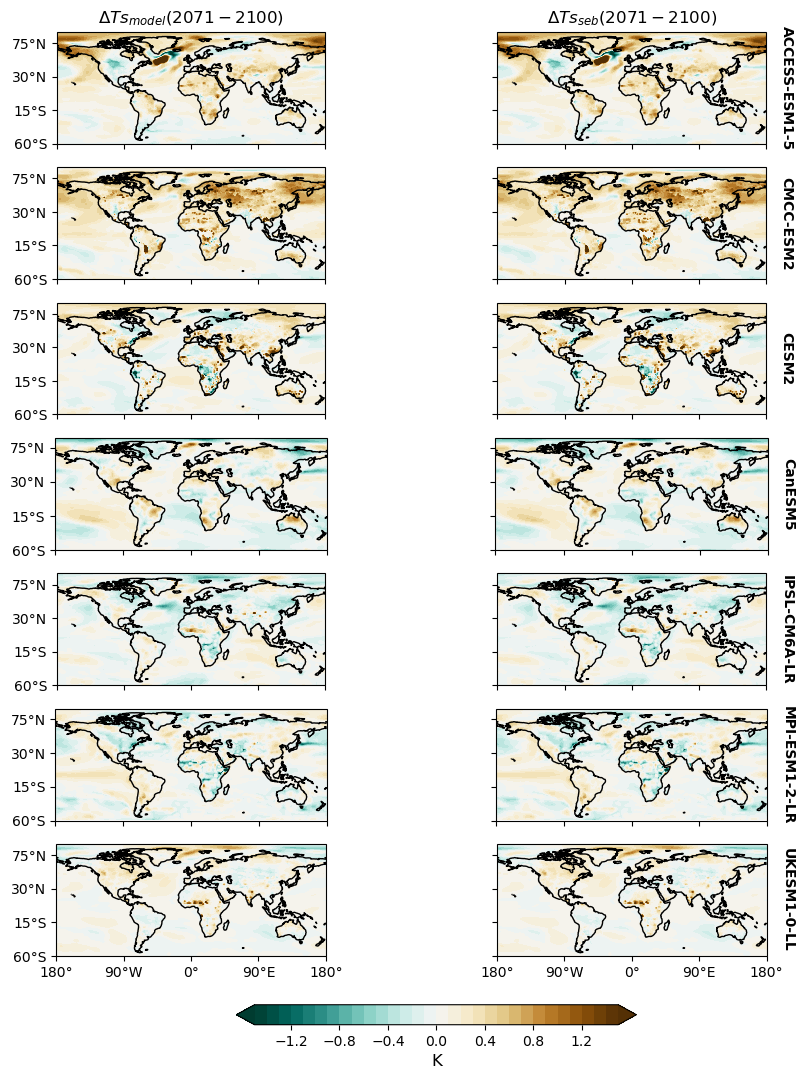

In [174]:
# Compare Temperature difference diagnosed from the model simulations (dT_model)
# with the one calculated from SEB decomposition (dT_seb)

# We can either plot the mean(2071-2100) or mean(2071-2100)-mean(2015) 

# dT_model = dT_model #.sel(time = slice("2071-01","2100-12")).mean(dim = "time") #- dT_model.sel(time = slice("2015-01","2015-12")).mean(dim = "time")
# dT_seb = dT_seb #.sel(time = slice("2071-01","2100-12")).mean(dim = "time") #- dT_seb.sel(time = slice("2015-01","2015-12")).mean(dim = "time")

to_plot = [dT_model_esm[0], dT_seb_esm[0], dT_model_esm[1], dT_seb_esm[1], dT_model_esm[2], dT_seb_esm[2], dT_model_esm[3], dT_seb_esm[3], 
            dT_model_esm[4], dT_seb_esm[4], dT_model_esm[5], dT_seb_esm[5], dT_model_esm[6], dT_seb_esm[6]]

cmap = "BrBG_r"
clevs=np.arange(-1.5,1.6,0.1)

# Create the figure 
width_inch = 10
height_inch = 10

fig, axs = plt.subplots(nrows=7, ncols=2, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.ravel()

for i, ax in enumerate(to_plot):
    
    # Add the cyclic point
    data = to_plot[i].sel(lat = slice(-60,90))
    data0,lons=add_cyclic_point(data,coord=data['lon'])
    
    map = axs[i].contourf(lons, data.lat, data0, clevs, transform = ccrs.PlateCarree(), cmap=cmap, extend='both')
    axs[i].coastlines()
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)    
    
    axs[0].set_title("$\Delta Ts_{model} (2071-2100)$")
    axs[1].set_title("$\Delta Ts_{seb} (2071-2100)$")
    
    if i%2 != 0: 
        idx = int((i/2)-0.5)
        axs[i].yaxis.set_label_position("right")
        axs[i].set_ylabel(models[idx], labelpad = 20, rotation = -90, weight='bold')
    
    axs[i].label_outer()
    
cb_ax = fig.add_axes([0.325, -0.03, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.1)
cbar.ax.set_xlabel("K", fontsize=12)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.0, hspace=0.25)
fig.tight_layout()

title = "SEB_Ts_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()


In [175]:
for i,mm in enumerate(models):
    print("SEB discrepancy ", mm, ":", str((to_plot[i+1].mean().values - to_plot[i].mean().values).round(3)))

SEB discrepancy  ACCESS-ESM1-5 : 0.005
SEB discrepancy  CMCC-ESM2 : 0.029
SEB discrepancy  CESM2 : 0.006
SEB discrepancy  CanESM5 : -0.129
SEB discrepancy  IPSL-CM6A-LR : 0.002
SEB discrepancy  MPI-ESM1-2-LR : -0.073
SEB discrepancy  UKESM1-0-LL : -0.0


#### Disentangle the different contribution of SEB factors

In [176]:
vars = ["albedo", "Sd", "Ld", "H", "LE"]

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3240714660.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

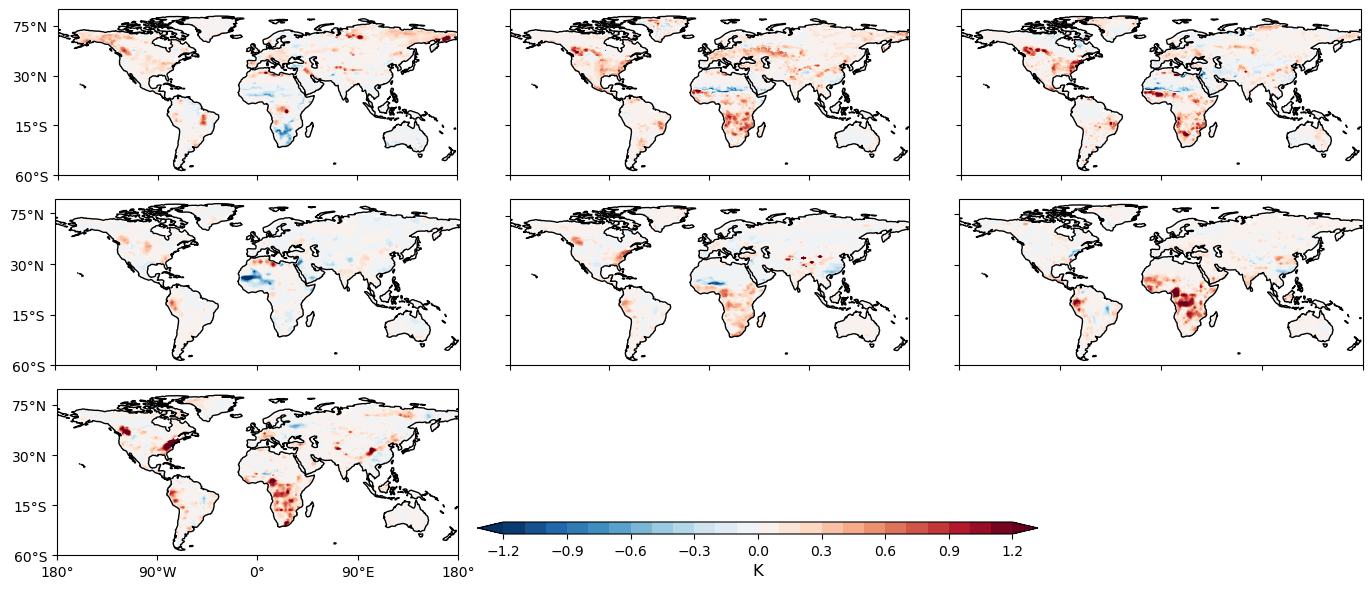

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3240714660.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

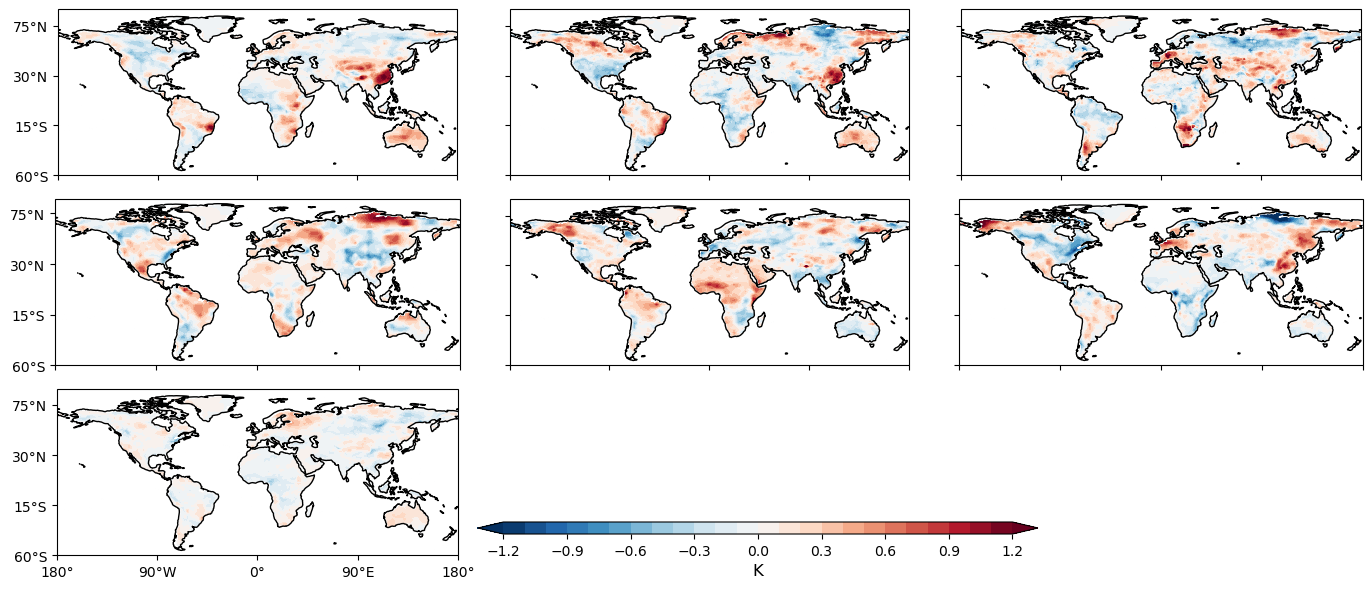

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3240714660.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

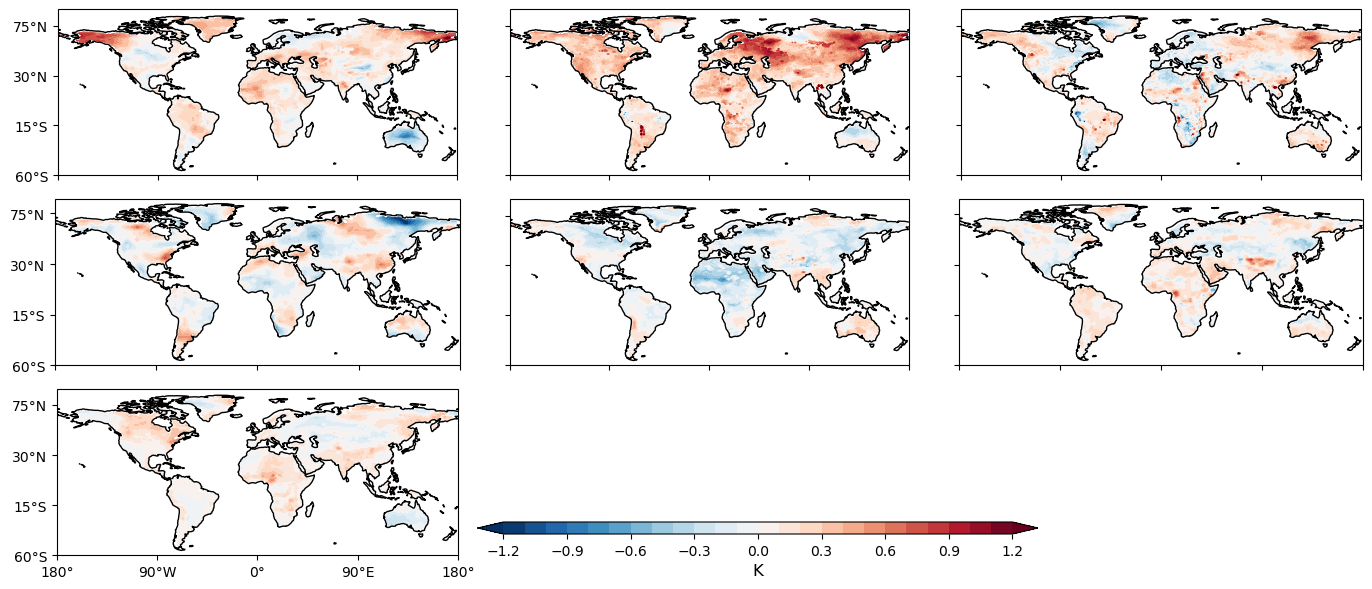

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3240714660.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

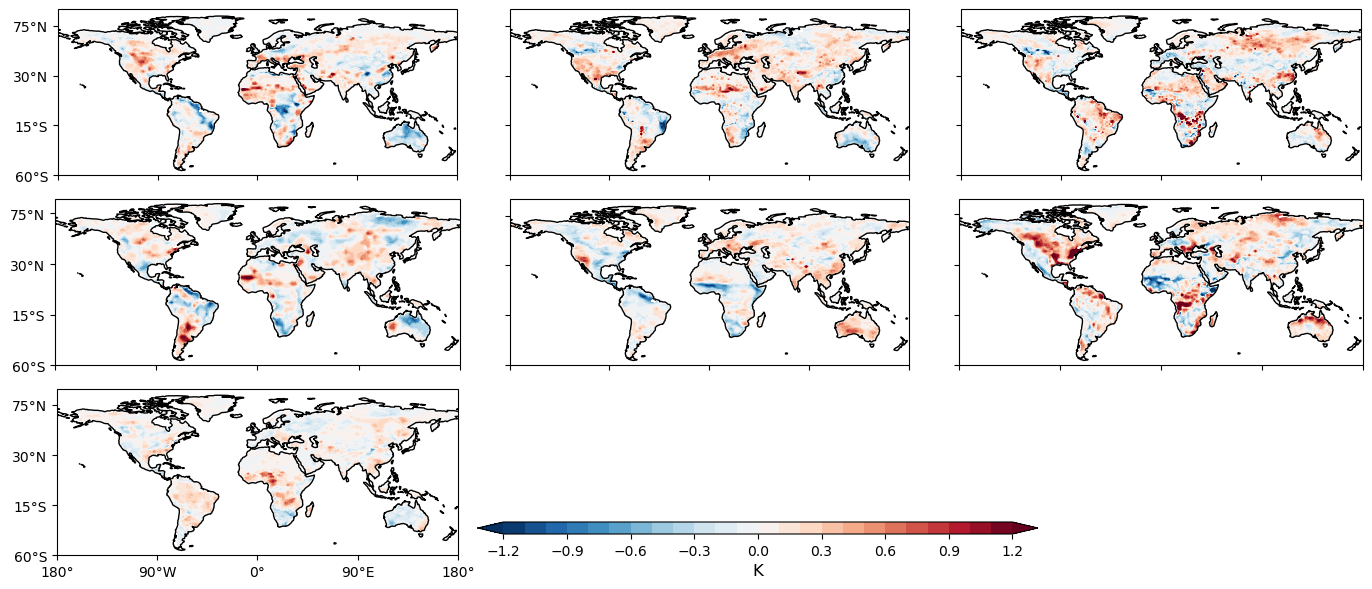

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3240714660.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

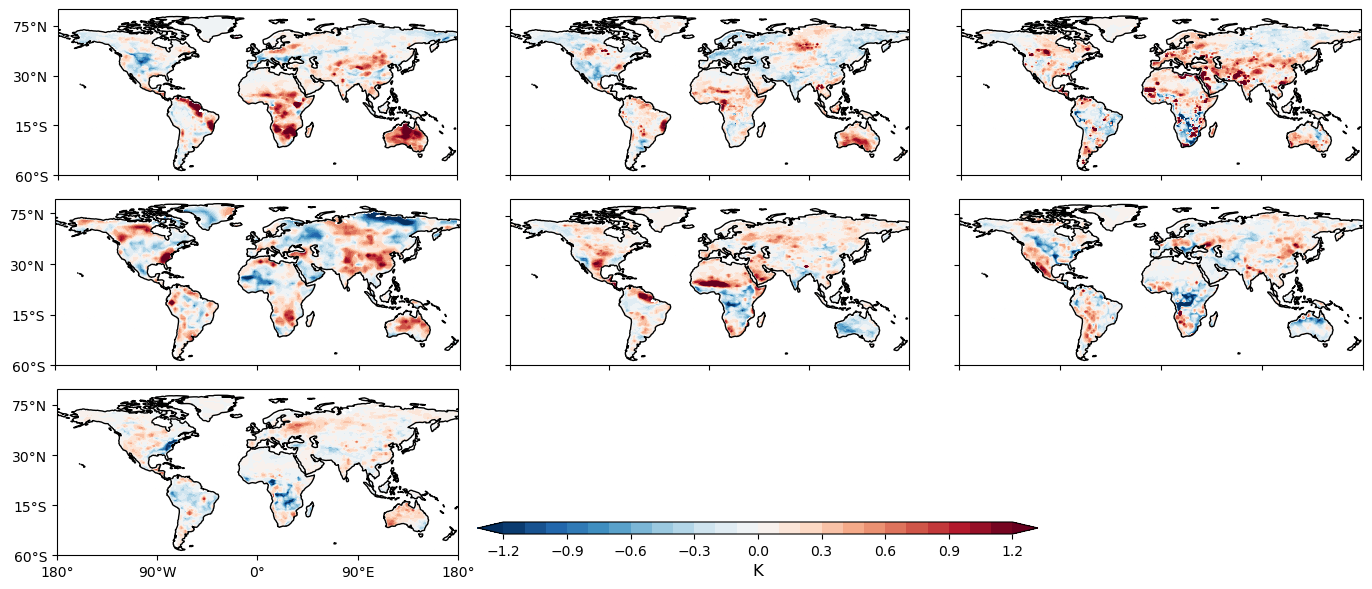

In [177]:
# Plot decomposition factors of SEB
    
cmap = "RdBu_r"
clevs = np.arange(-1.2,1.3,0.1)
width_inch = 14
height_inch = 6

for i,vv in enumerate(vars):
    
    fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
    axs = axs.ravel()
    
    for mm in np.arange(len(models)):
        
        data = seb_effect_esm[mm][vv].sel(lat = slice(-60,90))
        map = axs[mm].contourf(data.lon, data.lat, data.values, clevs, transform = ccrs.PlateCarree(), cmap=cmap, extend = "both")
        axs[mm].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
        axs[mm].coastlines()

        # Longitude labels
        axs[mm].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
        lon_formatter = cticker.LongitudeFormatter()
        axs[mm].xaxis.set_major_formatter(lon_formatter)

        # Latitude labels
        axs[mm].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
        lat_formatter = cticker.LatitudeFormatter()
        axs[mm].yaxis.set_major_formatter(lat_formatter)

        # Titles
        #axs[mm].set_title(models[mm])
        axs[mm].label_outer()

    for i in [7,8]:
        fig.delaxes(axs[i])
            
    
    fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

    cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
    cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)
    cbar.ax.set_xlabel("K", fontsize=12)

    #fig.suptitle(vv, y = .85)
    fig.tight_layout()
    
    title = "SEB_" + vv + "_esm"
    output_file = os.path.join(out_path, title) + ".png"
    plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
    plt.show()
    plt.close()

### SEB components in regions of Afforestation 

In [184]:
%%capture

seb_aff_mean = []
seb_aff_energy_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = (
        mask_treefrac_pos[m].notnull()
        & (mask_aff_water[m].notnull() | mask_aff_energy[m].notnull())
        & (xr_mw_ts[m] < 0.1)
)    # mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask

    masked = seb_effect_esm[m].where(mask)
    # masked1 = seb_effect_esm[m].where(mask1)
    content = [];# content1 = []
    for v in list(seb_effect_esm[m].data_vars)[:]:
        content.append(masked[v].weighted(cell_weight(masked)).mean(["lat","lon"]).data)
        # content1.append(masked1[v].weighted(cell_weight(masked1)).mean(["lat","lon"]).data)
    content = np.array(content)
    # content1 = np.array(content1)
    seb_aff_mean.append(content); 
    # seb_aff_energy_mean.append(content1)
    
seb_aff_mean = pd.DataFrame(seb_aff_mean, columns = list(seb_effect_esm[m].data_vars)[:], index = models)
# seb_aff_energy_mean = pd.DataFrame(seb_aff_energy_mean, columns = list(seb_effect_esm[m].data_vars)[:], index = models)

In [185]:
seb_aff_mean = pd.melt(seb_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
# seb_aff_water_mean["regime"] = "water-lim"

# seb_aff_energy_mean = pd.melt(seb_aff_energy_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
# seb_aff_energy_mean["regime"] = "energy-lim"

# seb_aff = pd.concat([seb_aff_water_mean, seb_aff_energy_mean], axis = 0)
seb_aff_mean = seb_aff_mean.groupby(['variable', 'models'])['value'].mean().reset_index()

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1389774511.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(vars_plot, rotation = 0)


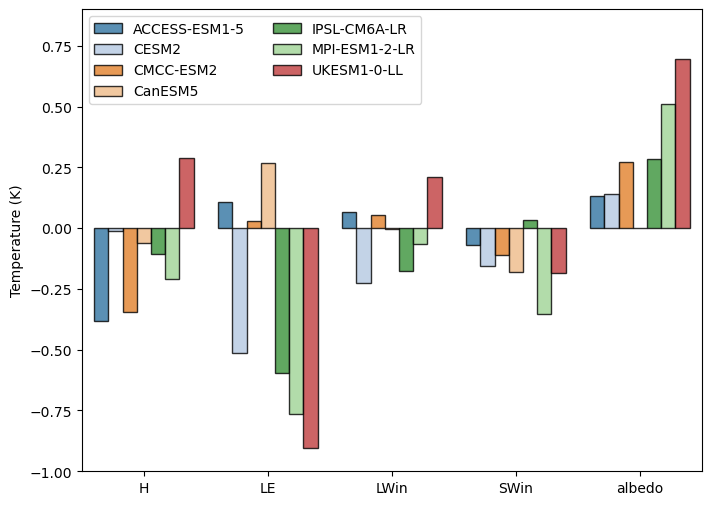

In [186]:
vars_plot = ["H", "LE", "LWin", "SWin", "albedo"]

fig = plt.figure(figsize=(8, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=seb_aff_mean, hue = "models",# errorbar=("pi", 50),
        x="variable", y="value", edgecolor = "black",
        palette="tab20", alpha=.8, 
    )
ax0.set_xticklabels(vars_plot, rotation = 0)
ax0.set_ylim(-1, 0.9)
ax0.legend(loc='upper left', ncol = 2, fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Temperature (K)")
title = "SEB components in afforested regions_growseas"
# ax0.set_title(title)
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

Contribution of original variables to SEB components

In [187]:
%%capture

delta_aff_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask

    masked = xr_delta[m].where(mask)
    content = [];
    for v in ["rsds", "rlds", "hfls", "hfss", "albedo"]:
        content.append(masked[v].weighted(cell_weight(masked)).mean(["lat","lon"]).data)
    content = np.array(content)
    delta_aff_mean.append(content); 
    
delta_aff_mean = pd.DataFrame(delta_aff_mean, columns = ["rsds", "rlds", "hfls", "hfss", "albedo"], index = models)
delta_aff_mean.columns = ["SWin", "LWin", "LE", "H", "albedo"]
delta_aff_mean = pd.melt(delta_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")

In [188]:
custom_order = ['H', 'LE', 'LWin', 'SWin']
delta_aff_mean = delta_aff_mean[delta_aff_mean['variable'].isin(custom_order)]
delta_aff_mean['variable'] = pd.Categorical(delta_aff_mean['variable'], categories=custom_order, ordered=True)
delta_aff_mean = delta_aff_mean.sort_values('variable')

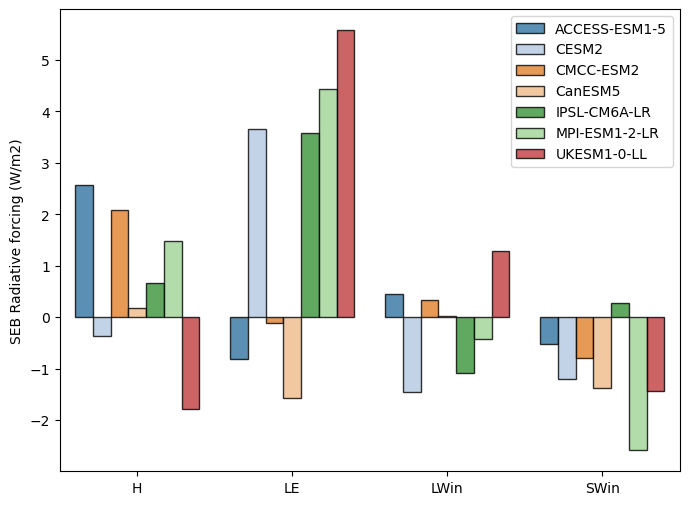

In [189]:

fig = plt.figure(figsize=(8, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=delta_aff_mean.sort_values("models"), hue = "models",# errorbar=("pi", 50),
        x="variable", y="value", edgecolor = "black",
        palette="tab20", alpha=.8, 
    )
# ax0.set_xticklabels(vars, rotation = 75)
# ax0.set_ylim(-0.9, 0.9)
ax0.legend(loc='upper right', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("SEB Radiative forcing (W/m2)")
title = "SEB Radiative forcing"
# ax0.set_title(title)
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

## Intrinsic Biophysical Mechanism (IBPM) decomposition

Taking the difference between the biogeophysical variables of ssp370-ssp126 and ssp370 \
Compute the Surface Energy Balance Decomposition to estimate the contribution to temperature.

The SEB equation can be decomposed as follows:

\begin{equation}
\Delta T_{{s}} = \frac{\lambda_{0}}{1 + f} (\Delta R_{n} - \Delta G) + \frac{-\lambda_{0}}{(1 + f)^2} (R_{n} - G)\Delta f_{1} +\frac{-\lambda_{0}}{(1 + f)^2} (R_{n} - G)\Delta f_{2} + \Delta T_{a}
\end{equation}

where 
\begin{equation}
\lambda_{0} = \frac{1}{4 \sigma T_{a}^3},f = \frac{\rho C_{p}}{4 \sigma T_{a}^3 \gamma_{a}}(1+ \frac{1}{\beta}), \gamma_{a}=\rho C_{p} \frac{T_{s} - T_{a}}{H}
\end{equation}

In [190]:
# Define Stefan-Boltzmann Constant (Wm^-2K^-4)
# Define Emissivity Constant
# Define air density Constant (Kgm^-3) (dry air, 0°C, https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6764509/)
# Define specific heat content (JKg^-1K^-1) (dry air, =0°C, https://pubs.aip.org/asa/jasa/article/76/2/555/669652/Variation-of-specific-heats-and-of-specific-heat)

sigma = 5.67*10**(-8)
eps = 0.97
rho = 1.2930
Cp = 1.0051*10**(-3) # it should be *10**(3), but in that case there is no correspondence with the modeled temperature, so we are considering (MJKg^-1K^-1)

In [191]:
# Equation Intrinsic Biophysical Mechanism (IBPM)

dT_ibpm_esm = []
dT_model_esm = []
ibpm_effect_esm = []

for m,mm in enumerate(models):
    ibpm_effects = xr.Dataset()
    
    xr_aff_seb = xr_aff_gs[m]#.sel(time = slice("2071-01","2100-12")).mean(dim = "time") # - xr_aff.sel(time = slice("2015-01","2015-12")).mean(dim = "time") 
    xr_ctl_seb = xr_ctl_gs[m]#.sel(time = slice("2071-01","2100-12")).mean(dim = "time") # - xr_ctl.sel(time = slice("2015-01","2015-12")).mean(dim = "time") 
    
    lambda0 = 1/(4*sigma*xr_ctl_seb.tas**3)
    delta_Ta = xr_aff_seb.tas - xr_ctl_seb.tas
    gamma_ctl = (rho*Cp)*(xr_ctl_seb.ts - xr_ctl_seb.tas)/xr_ctl_seb.hfss
    gamma_aff = (rho*Cp)*(xr_aff_seb.ts - xr_aff_seb.tas)/xr_aff_seb.hfss
    
    Rn_aff = (xr_aff_seb.rsds - xr_aff_seb.rsus) + eps*xr_aff_seb.rlds - eps*sigma*xr_aff_seb.ts**(4)
    Rn_ctl = (xr_ctl_seb.rsds - xr_ctl_seb.rsus) + eps*xr_ctl_seb.rlds - eps*sigma*xr_ctl_seb.ts**(4)
    
    G_aff = Rn_aff - xr_aff_seb.hfss - xr_aff_seb.hfls
    G_ctl = Rn_ctl - xr_ctl_seb.hfss - xr_ctl_seb.hfls
    
    # gamma_ctl = (rho*Cp)*(xr_ctl_seb.ts - xr_ctl_seb.tas)/xr_ctl_seb.hfls
    # gamma_aff = (rho*Cp)*(xr_aff_seb.ts - xr_aff_seb.tas)/xr_aff_seb.hfls

    beta_ctl = xr_ctl_seb.hfss * xr_ctl_seb.hfls**(-1)
    beta_aff = xr_aff_seb.hfss * xr_aff_seb.hfls**(-1)

    delta_beta = beta_aff - beta_ctl
    delta_gamma = gamma_aff - gamma_ctl

    f = (rho*Cp)*lambda0*gamma_ctl**(-1)*(1+1/beta_ctl)

    delta_Rn = Rn_aff - Rn_ctl
    delta_G = G_aff - G_ctl
    # delta_Ta = xr_aff_seb.tas - xr_ctl_seb.tas

    delta_f1 = -f * (delta_gamma)*gamma_ctl**(-1)
    delta_f2 = -(rho*Cp) * lambda0 * (delta_beta)*beta_ctl**(-2)
    
    dT_model = (xr_aff_seb.ts - xr_ctl_seb.ts)

    dT_ibpm = lambda0*(1+f)**(-1) * (delta_Rn - delta_G) + -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f1 + -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f2 + delta_Ta
    
    ibpm_effects["RF"] = lambda0*(1+f)**(-1) * (delta_Rn - delta_G)
    ibpm_effects["AerodRes"] = -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f1
    ibpm_effects["BowenRatio"] = -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f2
    ibpm_effects["AtmFeed"] = delta_Ta
    
    dT_model_esm.append(dT_model)
    dT_ibpm_esm.append(dT_ibpm)
    ibpm_effect_esm.append(ibpm_effects)

<>:43: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/700411745.py:43: SyntaxWarning: invalid escape sequence '\D'
  axs[0].set_title("$\Delta Ts_{model} (2071-2100)$")
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/700411745.py:44: SyntaxWarning: invalid escape sequence '\D'
  axs[1].set_title("$\Delta Ts_{ibpm} (2071-2100)$")
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.

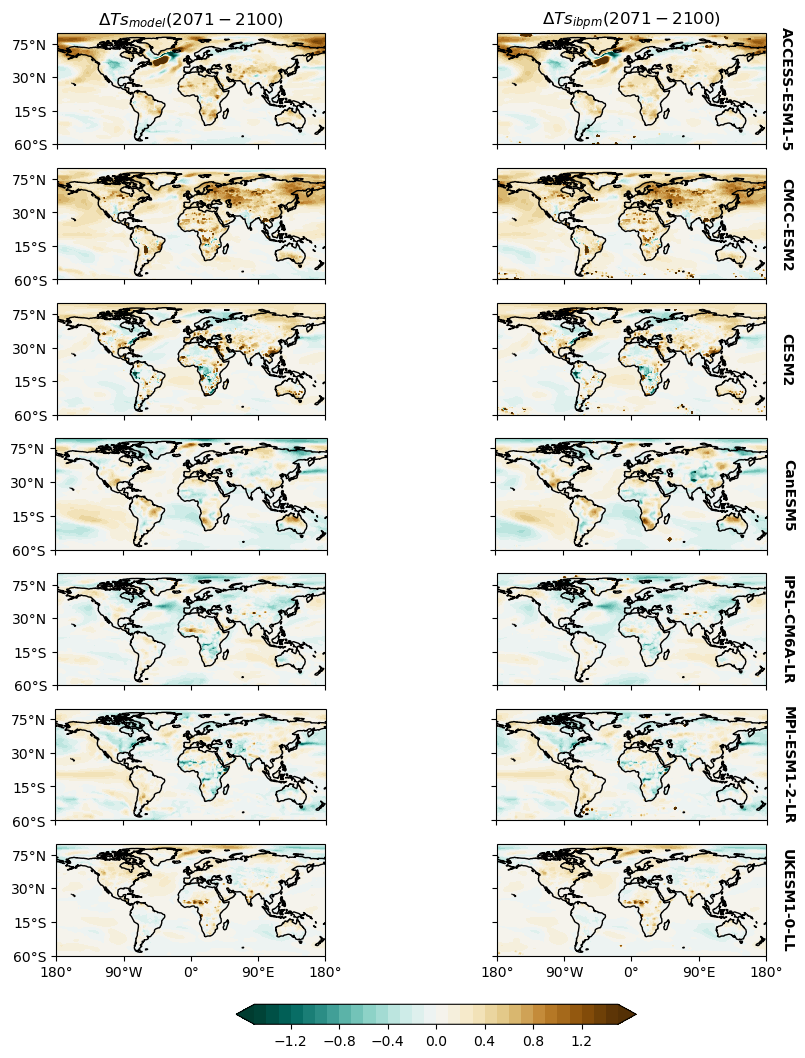

In [192]:

to_plot = [dT_model_esm[0], dT_ibpm_esm[0], dT_model_esm[1], dT_ibpm_esm[1], dT_model_esm[2], dT_ibpm_esm[2], dT_model_esm[3], dT_ibpm_esm[3],
            dT_model_esm[4], dT_ibpm_esm[4], dT_model_esm[5], dT_ibpm_esm[5], dT_model_esm[6], dT_ibpm_esm[6]]

cmap = "BrBG_r"
clevs=np.arange(-1.5,1.6,0.1)

# Create the figure 
width_inch = 10
height_inch = 10

fig, axs = plt.subplots(nrows=7, ncols=2, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.ravel()

for i, ax in enumerate(to_plot):
    
    # Add the cyclic point
    data = to_plot[i].sel(lat = slice(-60,90))
    data0,lons=add_cyclic_point(data,coord=data['lon'])
       
    map = axs[i].contourf(lons, data.lat, data0, clevs, transform = ccrs.PlateCarree(), cmap=cmap, extend='both')
    axs[i].coastlines()

    # if i == 0:
    #     hatch = xr_mw_ts[i]
    #     sign = np.ma.masked_greater(hatch, 0.1)
    #     map1 = axs[i].pcolor(lons, data.lat, sign, hatch = '///', transform = ccrs.PlateCarree(), alpha=0)
    # if i ==2 or i == 4 or i == 6:
    #     hatch = xr_mw_ts[np.int32(i/2)]
    #     sign = np.ma.masked_greater(hatch, 0.1)
    #     map1 = axs[i].pcolor(lons, data.lat, sign, hatch = '///', transform = ccrs.PlateCarree(), alpha=0)        
    # else: None
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)    
    
    axs[0].set_title("$\Delta Ts_{model} (2071-2100)$")
    axs[1].set_title("$\Delta Ts_{ibpm} (2071-2100)$")
    
    if i%2 != 0: 
        idx = int((i/2)-0.5)
        axs[i].yaxis.set_label_position("right")
        axs[i].set_ylabel(models[idx], labelpad = 20, rotation = -90, weight='bold')
    
    axs[i].label_outer()

cb_ax = fig.add_axes([0.325, -0.03, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.1)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.0, hspace=0.25)
fig.tight_layout()

title = "IBPM_Ts_esm"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

#### Disentangle the different contributions of IBPM

In [193]:
vars = ["RF", "AerodRes", "BowenRatio", "AtmFeed"]

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1831426942.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

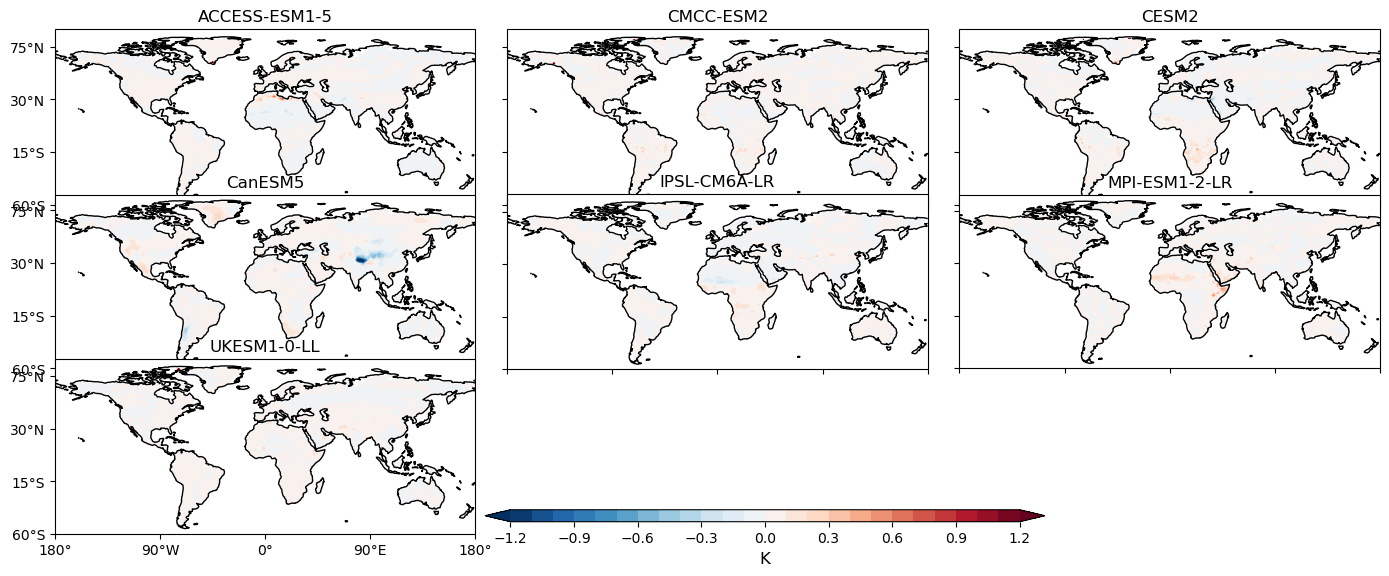

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1831426942.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

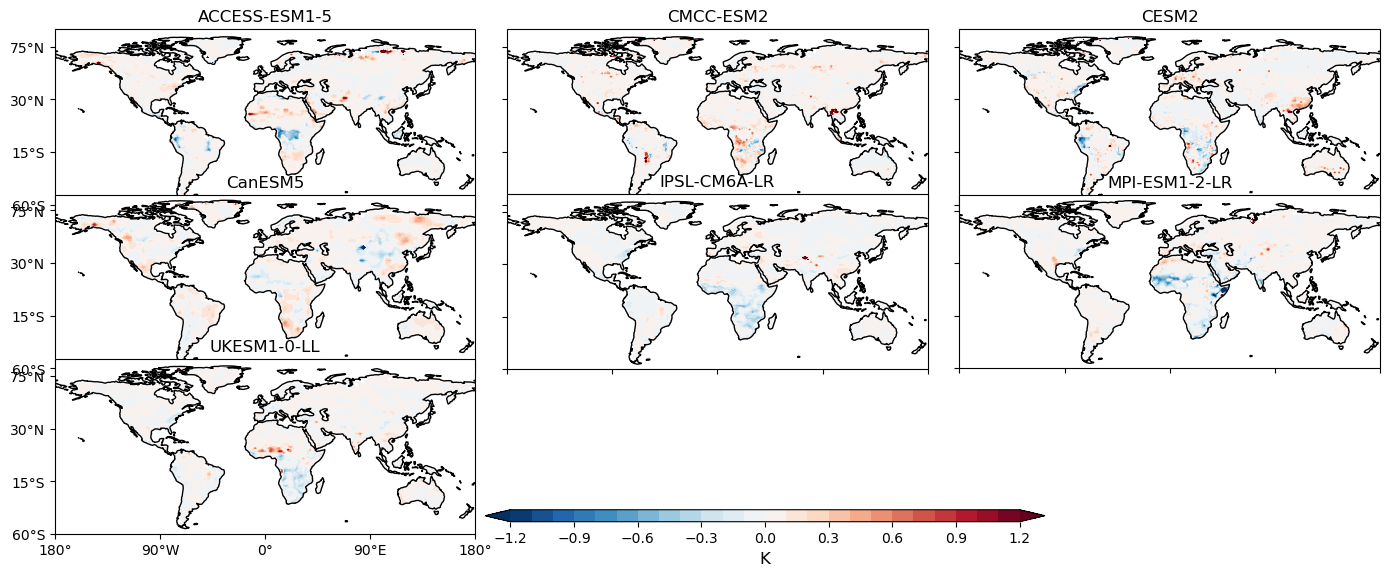

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1831426942.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

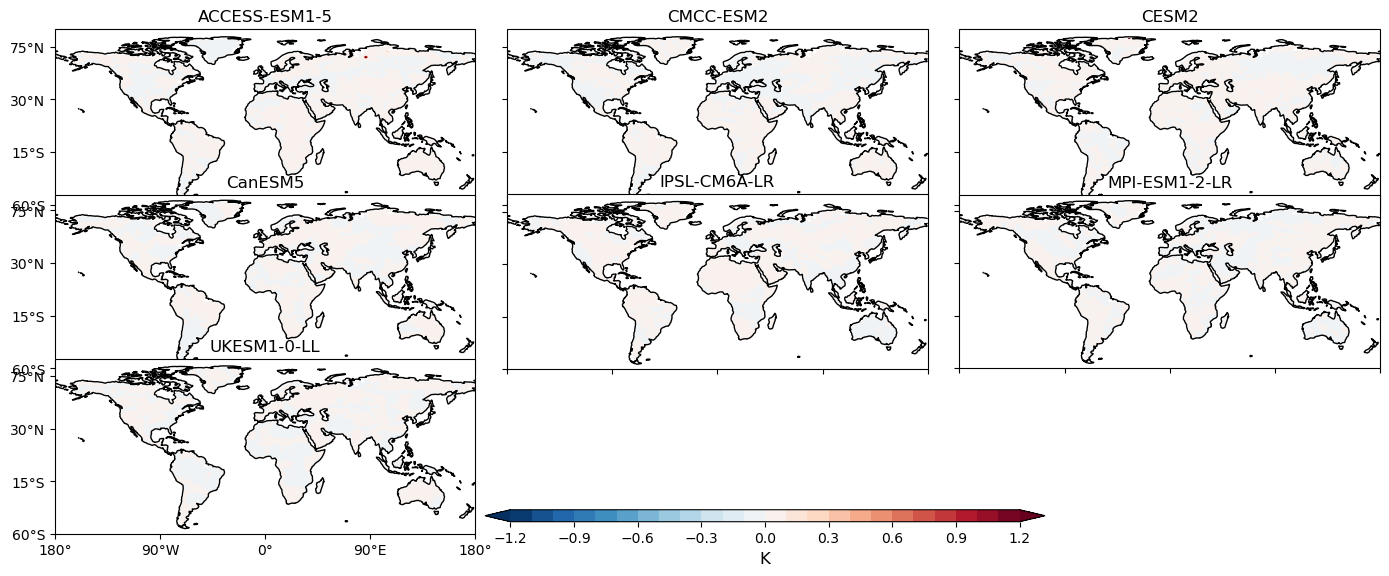

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/1831426942.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/matteomastropierro/minicon

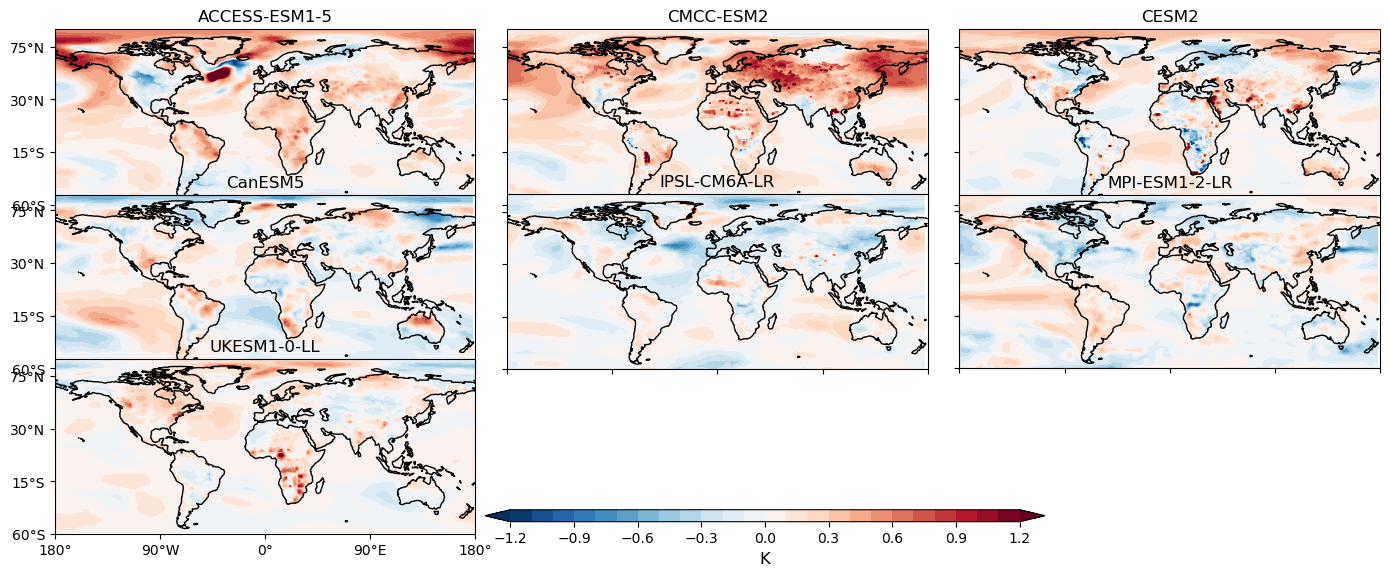

In [194]:
# Plot decomposition factors of SEB
    
cmap = "RdBu_r"
clevs = np.arange(-1.2,1.3,0.1)
width_inch = 14
height_inch = 6

for i,vv in enumerate(vars):
    
    fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
    axs = axs.ravel()
    
    for mm in np.arange(len(models)):
        
        data = ibpm_effect_esm[mm][vv]
        map = axs[mm].contourf(data.lon, data.lat, data.values, clevs, transform = ccrs.PlateCarree(), cmap=cmap, extend = "both")
        if vv != "AtmFeed":
            axs[mm].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
        axs[mm].coastlines()

        # Longitude labels
        axs[mm].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
        lon_formatter = cticker.LongitudeFormatter()
        axs[mm].xaxis.set_major_formatter(lon_formatter)

        # Latitude labels
        axs[mm].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
        lat_formatter = cticker.LatitudeFormatter()
        axs[mm].yaxis.set_major_formatter(lat_formatter)

        # Titles
        axs[mm].set_title(models[mm])
        axs[mm].label_outer()
        
    for i in [7,8]:
        fig.delaxes(axs[i])
            
    
    fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

    cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
    cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)
    cbar.ax.set_xlabel("K", fontsize=12)

    #fig.suptitle(vv, y = .85)
    fig.tight_layout()
    
    title = "IBPM_" + vv + "_esm"
    output_file = os.path.join(out_path, title) + ".png"
    plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
    plt.show()
    plt.close()

#### IBPM components in regions of Afforestation

In [195]:
ibpm_aff_mean = []
# ibpm_aff_energy_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask
    # mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull() & np.ma.masked_less(xr_mw_ts[m], 0.1).mask

    masked = ibpm_effect_esm[m].where(mask)
    # masked1 = ibpm_effect_esm[m].where(mask1)
    content = [];# content1 = []
    for v in list(ibpm_effect_esm[m].data_vars)[:]:
        content.append(masked[v].weighted(cell_weight(masked)).mean(["lat","lon"]).data)
        # content1.append(masked1[v].weighted(cell_weight(masked1)).mean(["lat","lon"]).data)
    content = np.array(content)
    # content1 = np.array(content1)
    ibpm_aff_mean.append(content); 
    # ibpm_aff_energy_mean.append(content1);
    
ibpm_aff_mean = pd.DataFrame(ibpm_aff_mean, columns = list(ibpm_effect_esm[m].data_vars)[:], index = models)
# # ibpm_aff_energy_mean = pd.DataFrame(ibpm_aff_energy_mean, columns = list(ibpm_effect_esm[m].data_vars)[:], index = models)

In [196]:
ibpm_aff_mean = pd.melt(ibpm_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
# ibpm_aff_water_mean["regime"] = "water-lim"

# ibpm_aff_energy_mean = pd.melt(ibpm_aff_energy_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
# ibpm_aff_energy_mean["regime"] = "energy-lim"

# ibpm_aff = pd.concat([ibpm_aff_water_mean, ibpm_aff_energy_mean], axis = 0)
ibpm_aff_mean = ibpm_aff_mean.groupby(['variable', 'models'])['value'].mean().reset_index()

## Plot SEB & IBPM in 2 panels

In [197]:
toplot = pd.concat([seb_aff_mean, ibpm_aff_mean], axis = 0)
toplot = toplot[~toplot["variable"].isin(["RF", "BowenRatio"])]

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_11379/3756358998.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(vars_plot)


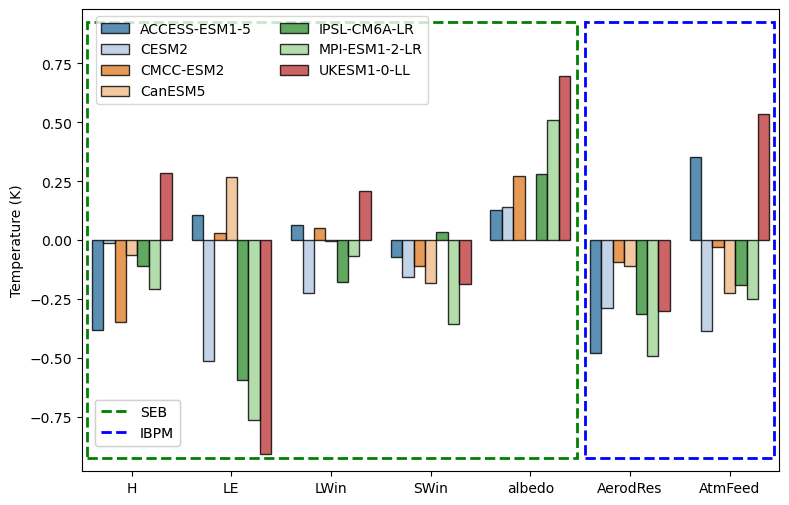

In [198]:
import matplotlib.patches as patches
from matplotlib.lines import Line2D

vars_plot = ["H", "LE", "LWin", "SWin", "albedo", "AerodRes", "AtmFeed"]

fig = plt.figure(figsize=(9, 6))
ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=toplot, hue = "models",# errorbar=("pi", 50),
        x="variable", y="value",
        palette="tab20", alpha=.8, edgecolor = "black"
    )
# ax0.set_xticklabels(vars, rotation = 75)
ax0.set_ylim(-0.98, 0.98)
ax0.set_xlabel("",)
ax0.set_ylabel("Temperature (K)")
ax0.set_xticklabels(vars_plot)
title = "SEB & IBPM decomposition_growseas"
# ax0.set_title(title)

# Coordinates for rectangles
first_group_indices = [0, 1, 2, 3, 4]
second_group_indices = [5, 6]

# Get the positions and width of bars
positions = ax0.get_xticks()
width = (positions[1] - positions[0]) * 0.9  # Approximate width of each bar

# Draw green dotted square around the first 4 variables
rect1 = patches.Rectangle(
    (positions[first_group_indices[0]] - width/2, -0.925),
    width * len(first_group_indices)+0.42,
    1.85,
    linewidth=2,
    edgecolor='green',
    linestyle='--',
    facecolor='none'
)
ax0.add_patch(rect1)

# Draw blue dotted square around the last 2 variables
rect2 = patches.Rectangle(
    (positions[second_group_indices[0]] - width/2, -0.925),
    width * len(second_group_indices)+0.1,
    1.85,
    linewidth=2,
    edgecolor='blue',
    linestyle='--',
    facecolor='none'
)
ax0.add_patch(rect2)

ax0.legend(loc='upper left', ncol = 2, bbox_to_anchor=(0.01, 1), fontsize = 10)
legend1 = ax0.get_legend()

# Custom legend
custom_lines = [
    Line2D([0], [0], color='green', lw=2, linestyle='--', label='SEB'),
    Line2D([0], [0], color='blue', lw=2, linestyle='--', label='IBPM')
]

# Adding a second legend for the custom lines
legend1plus = ax0.legend(handles=custom_lines, loc='upper right', bbox_to_anchor=(0.15, 0.17), fontsize=10)

ax0.add_artist(legend1)
ax0.add_artist(legend1plus)

output_file = os.path.join(out_path, title) + "_growseas.png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()